# 01 · The corpus, and getting clean text out of it

Before any retrieval happens, the documents have to become text that an embedding model and an
LLM can read. For English and French that's mostly easy. For Arabic PDFs it isn't, and this notebook
shows the problem, the fix, and how much it helps, measured rather than eyeballed.

The corpus is three "courses", one per language, built from Wikipedia articles (CC BY-SA 4.0)
so that anyone can download it again with `scripts/fetch_corpus.py`:

- **English**: Machine Learning (14 articles)
- **French**: Systèmes d'exploitation et bases de données (14 articles)
- **Arabic**: الشبكات والأمن والخوارزميات (networks, security and algorithms, 13 articles)

In each language, half the articles are stored as **PDFs** (rendered by Wikipedia) and half as
**markdown notes** (Wikipedia's plain-text export), so both loaders get real use.

In [1]:
import sys
sys.path.insert(0, "../src")

from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf

from course_rag import plots
from course_rag.config import FIGURES_DIR, MANIFEST_PATH, RAW_DIR, REFERENCE_TEXT_DIR
from course_rag.ingest import chunk_documents, clean_wiki_math, load_corpus, split_sections
from course_rag.pdf import extract_pdf
from course_rag.text import normalize_for_match

plots.setup()
pd.set_option("display.max_colwidth", 120)
manifest = pd.read_csv(MANIFEST_PATH)
manifest.groupby(["lang", "course", "format"]).size().unstack()

,format,md,pdf
lang,course,,
ar,الشبكات والأمن والخوارزميات,6,7
en,Machine Learning,7,7
fr,Systèmes d'exploitation et bases de données,7,7


## The right-to-left problem

A PDF doesn't store sentences. It stores glyphs and where to draw them. Extraction tools rebuild the
reading order from those positions, and for Arabic lines that mix in Latin words (which is most
lines in a technical text: "TCP", "(Local area network)"…) PyMuPDF gets the order of the
direction runs wrong. Here is the same paragraph, first as PyMuPDF returns it, then after the repair
in `course_rag/pdf.py`:

In [2]:
path = RAW_DIR / "ar/shabakat-hasoub.pdf"
for repair, label in [(False, "PyMuPDF as is"), (True, "after the repair")]:
    first_paragraph = extract_pdf(path, repair_rtl=repair).text.split("\n\n")[1]
    print(f"{label}:\n\n{first_paragraph[:330]}\n")

PyMuPDF as is:

شبكة الحاسوب نظام لربط جهازين أو أكثر باستخدام إحدى تقنيات نظم الاتصالات من أجل تبادل المعلومات والموارد والبيانات بينها المتاحة الطابعة أو البرامج التطبيقية أي ًا كان نوعها وكذلك تسمح للشبكة مثل الآلة وبشكل عام تعتبر دراسة.بالتواصل المباشر بين المستخدمين .علم الاتصالات شبكات الحاسوب أحد فروع الشبكة قريبة جد ًا من بعضها الحاسوب 

after the repair:

شبكة الحاسوب نظام لربط جهازين أو أكثر باستخدام إحدى تقنيات نظم الاتصالات من أجل تبادل المعلومات والموارد والبيانات بينها المتاحة للشبكة مثل الآلة الطابعة أو البرامج التطبيقية أيا كان نوعها وكذلك تسمح بالتواصل المباشر بين المستخدمين. وبشكل عام تعتبر دراسة شبكات الحاسوب أحد فروع علم الاتصالات.



Same paragraph, same words, but in the raw version the phrases are shuffled: the sentence about sharing a
printer is cut in two, and «وبشكل عام تعتبر دراسة» ("in general, the study of…") lands inside another sentence. The embedding model still sees the right words, but
the LLM reads a scrambled sentence, and a quoted snippet in a citation would be unreadable.

**The repair** works at character level. PyMuPDF's `rawdict` mode gives every character with its
bounding box. For a block that is mostly Arabic:

1. sort each line's characters by x position, **right to left**. That is the reading order for Arabic;
2. that also reverses every run of Latin letters and digits (they read left to right inside
   the Arabic sentence), so flip those runs back;
3. drop the short-vowel marks (ḥarakāt), plus the fake space PyMuPDF sometimes inserts in front of one
   (`تع ّلم` → `تعلم`). Retrieval normalises vowel marks away anyway.

Two smaller things happen for every language: text smaller than the body font is skipped (figure captions
and infobox tables), and headings are detected from **bold + larger than body text**. Size alone
misfired on lines containing a formula, because some of their glyphs are big.

## Measuring it

For every PDF document I also downloaded Wikipedia's plain-text version of the same article. That is
a clean reference, so extraction quality can be scored. Two numbers per document:

- **word F1**: are the right words there (bag of words)?
- **word-bigram F1**: are they in the right order? A scrambled sentence keeps its words but loses its bigrams.

Both texts go through the same cleaning (drop reference sections, normalise punctuation) before comparison.

In [3]:
def ngram_f1(a, b, n):
    A = Counter(zip(*[a[i:] for i in range(n)]))
    B = Counter(zip(*[b[i:] for i in range(n)]))
    overlap = sum((A & B).values())
    p, r = overlap / max(1, sum(A.values())), overlap / max(1, sum(B.values()))
    return 2 * p * r / max(1e-9, p + r)

def words(text, title):
    return normalize_for_match(" ".join(s.body for s in split_sections(text, title))).split()

rows = []
for r in manifest[manifest.format == "pdf"].itertuples():
    ref = words((REFERENCE_TEXT_DIR / r.path).with_suffix(".md").read_text(encoding="utf-8"), r.title)
    for repair in (False, True):
        ext = words(extract_pdf(RAW_DIR / r.path, repair_rtl=repair).text, r.title)
        rows.append({"doc_id": r.doc_id, "lang": r.lang, "extraction": "repaired" if repair else "PyMuPDF as is",
                     "word F1": ngram_f1(ext, ref, 1), "bigram F1": ngram_f1(ext, ref, 2)})
quality = pd.DataFrame(rows)
summary = quality.groupby(["lang", "extraction"])[["word F1", "bigram F1"]].mean().round(3)
summary

word F1  bigram F1
lang extraction                       
ar   PyMuPDF as is    0.905      0.752
     repaired         0.946      0.932
en   PyMuPDF as is    0.849      0.827
     repaired         0.849      0.827
fr   PyMuPDF as is    0.965      0.963
     repaired         0.965      0.963

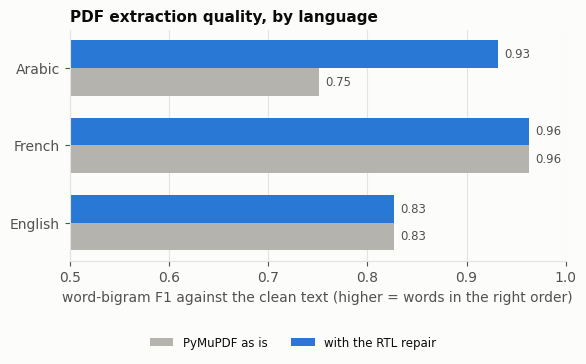

In [4]:
langs = ["ar", "fr", "en"]
pivot = quality.groupby(["lang", "extraction"])["bigram F1"].mean().unstack().loc[langs]
fig, ax = plt.subplots(figsize=(6.4, 3.0))
y = np.arange(len(langs))
h = 0.36
b1 = ax.barh(y + h / 2, pivot["PyMuPDF as is"], height=h, color=plots.MUTED, label="PyMuPDF as is")
b2 = ax.barh(y - h / 2, pivot["repaired"], height=h, color=plots.SERIES[0], label="with the RTL repair")
plots.label_bars(ax, b1); plots.label_bars(ax, b2)
ax.set_yticks(y, [plots.LANG_LABELS[l] for l in langs]); ax.invert_yaxis()
ax.set_xlim(0.5, 1.0); ax.set_xlabel("word-bigram F1 against the clean text (higher = words in the right order)")
ax.grid(axis="y", visible=False)
ax.set_title("PDF extraction quality, by language")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.28), ncol=2, fontsize=8.5)
fig.savefig(FIGURES_DIR / "pdf_extraction_quality.png")
plt.show()

The repair lifts Arabic word-order quality from about **0.75 to 0.93** and leaves French and English exactly
where they were. That's expected: their blocks never take the right-to-left path.

English scores lower than French for a reason unrelated to direction: English articles are
full of formulas, which the PDF draws as images (no text) while the reference text spells them out in LaTeX.

**What's still broken.** Some Arabic words keep a stray space (`م ضيفين` for `مضيفين`). I tried two wider
rules for removing those spaces. Both fixed the examples I was looking at, and both made the overall
bigram F1 *worse* (0.903 and 0.918 vs 0.932) because they also deleted real word boundaries. So I kept the
narrow rule. Measuring first is what caught that.

## A second cleaning problem: formulas in the plain-text export

The markdown notes have their own issue. Wikipedia's plain-text export prints every formula as its
rendered MathML, one symbol per line, and then its LaTeX source. Left in, a single formula can fill half
a chunk with noise like this:

In [5]:
raw = (RAW_DIR / "fr/ordonnancement.md").read_text(encoding="utf-8")
i = raw.find("Si \n")
print(repr(raw[i:i + 160]))
print()
print(clean_wiki_math(raw[i:i + 400])[:160])

"Si \n  \n    \n      \n        n\n      \n    \n    {\\displaystyle n}\n  \n tâches doivent être exécutées de manière simultanée et qu'il est physiquement impossible pour"

Si n tâches doivent être exécutées de manière simultanée et qu'il est physiquement impossible pour l'ordinateur de traiter plus d'une tâche simultanément, le no


`clean_wiki_math` keeps only the LaTeX, inline, and glues the sentence back together. It recognises
formula residue by its indentation, so short real lines (`GET`, `POST` in the HTTP article) survive.
Before this fix the corpus had 1,336 chunks; after it, 1,267. Those 69 chunks were mostly
formula debris.

## Chunks

Each section is cut into ~1,000-character chunks with 150 characters of overlap, never across
a section boundary. Every chunk starts with a header, `Document title > Section > Subsection`,
which costs a few tokens and tells both the retriever and the LLM where the passage comes from.
Chunk sizes of 500 and 1,500 are compared in notebook 02.

In [6]:
docs = load_corpus()
chunks = chunk_documents(docs)
stats = pd.DataFrame([{"lang": c.metadata["lang"], "format": c.metadata["format"], "chars": len(c.metadata["body"])}
                      for c in chunks])
table = stats.groupby("lang").agg(chunks=("chars", "size"), median_chars=("chars", "median"))
table["documents"] = manifest.groupby("lang").size()
table["text_chars"] = pd.Series({l: sum(len(d.text) for d in docs if d.lang == l) for l in langs})
table.loc[langs]

,chunks,median_chars,documents,text_chars
lang,,,,
ar,164,726.5,13,109300
fr,319,694.0,14,207469
en,784,716.0,14,524197


In [7]:
example = next(c for c in chunks if c.metadata["doc_id"] == "ar/tcp" and "المصافحة" in c.page_content)
print(example.metadata["chunk_id"], "· page", example.metadata["page"], "\n")
print(example.page_content[:500])

ar/tcp#006 · page 3 

بروتوكول التحكم بالإرسال > ترويسة التي سي بي
2) يقيم رابطة (اتصال) بين المرسل والمستقبل قبل الشروع بالإرسال: يستخدم التي سي بي تقنية المصافحة من أجل إقامة رابطة أو اتصال مع المستقبل، حيث يقوم بإرسال 3 طرود (3 إشارات مصافحة) بين كل من المرسل والمستقبل:

1- يقوم المرسل بإرسال طرد طلب فتح رابطة إلى المستقبل.

2- يقوم المستقبل بتأكيد هذا الطلب والموافقة عليه (إن كان يستطيع فتح رابطة وليس مشغولا بعمليات نقل أخرى مع غيره من العقد على الشبكة).

3- يرد المرسل على المستقبل بإشارة تأكيد أخيرة ليدل على أنه


The corpus is uneven, as real course material would be: the English articles are long, and Arabic
Wikipedia covers these topics much more thinly, so Arabic is only 13% of the chunks. That matters later.
A retriever that slightly prefers English text gets punished hardest on questions whose answer is in
one of the few Arabic chunks.